# Определение возраста покупателей

Описание проекта

Сетевой супермаркет «Хлеб-Соль» внедряет систему компьютерного зрения для обработки фотографий покупателей. Фотофиксация в прикассовой зоне поможет определять возраст клиентов, чтобы:

- Анализировать покупки и предлагать товары, которые могут заинтересовать покупателей этой возрастной группы;
- Контролировать добросовестность кассиров при продаже алкоголя.

Требуется построить модель, которая по фотографии определит приблизительный возраст человека. В вашем распоряжении набор фотографий людей с указанием возраста.

## Исследовательский анализ данных

In [1]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
import seaborn as sns

In [2]:
#Загрузка данных
labels = pd.read_csv('/datasets/faces/labels.csv')
train_datagen = ImageDataGenerator(rescale=1./255)
train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=labels,
        directory='/datasets/faces/final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        seed=12345) 

Found 7591 validated image filenames.


In [3]:
labels.sample(5)

,file_name,real_age
7058,007071.jpg,90
5664,005664.jpg,16
2546,002546.jpg,33
2277,002277.jpg,13
2716,002716.jpg,20


In [4]:
labels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  7591 non-null   object
 1   real_age   7591 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.7+ KB


In [5]:
labels.isna().mean()

file_name    0.0
real_age     0.0
dtype: float64

In [6]:
labels.shape

(7591, 2)

In [7]:
labels.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
real_age,7591.0,31.201159,17.14506,1.0,20.0,29.0,41.0,100.0


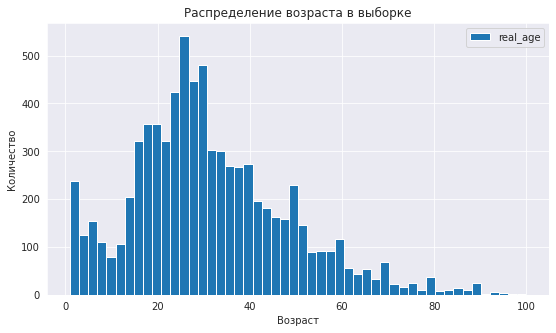

In [8]:
#Гистограмма распределения возрастов в выборке
sns.set_style('dark')
labels.plot(kind='hist',figsize=(9,5),bins=50, grid=True)
plt.title('Распределение возраста в выборке')
plt.xlabel('Возраст')
plt.ylabel('Количество')
plt.show()

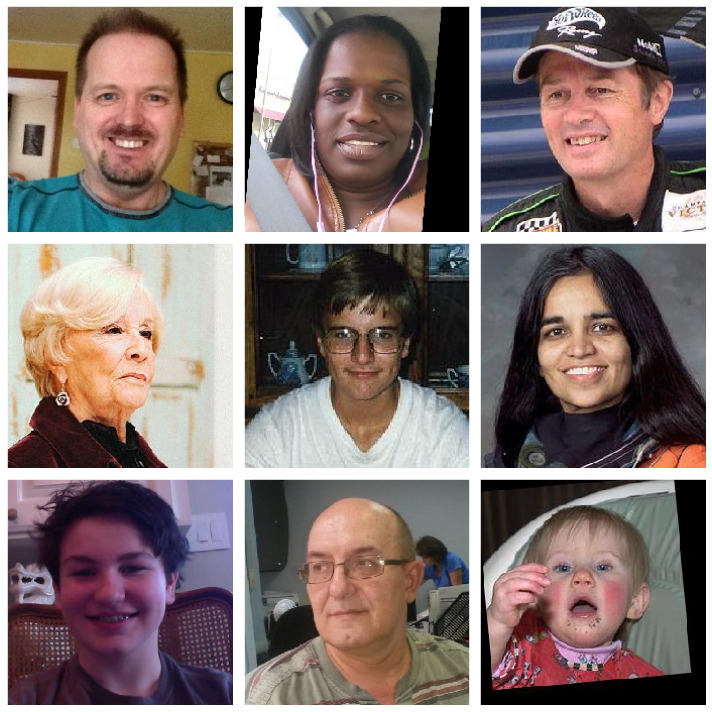

In [9]:
#Вывод на экран 15 фотографий
features, target = next(train_gen_flow)

fig = plt.figure(figsize=(10,10))
for i in range(9):
    fig.add_subplot(3, 3, i+1)
    plt.imshow(features[i])
    plt.xticks([])
    plt.yticks([])
    plt.tight_layout()

# Вывод:

- Количество фотографий в выборке 7591.
- Средний возраст на фото 31 год.
- Пропусков в датасете нет.
- Фотографии разняться по качеству, освещённости, контрасту, некоторые повернуты по диагонали. Часть фото чёрно-белые, часть цветные.
- Присутствуют фотографии младенцев и детей, что для требуемой задачи "Рекомендации товаров" не подойдет, фото детей до 10 лет можно не использовать для обучения модели. А вот фото подростков от 10 лет и выше, подойдут для выполнения задачи "Контроль продажи алкоголя".
- Количество фотографий возраста 60+ очень мало, что приведет к снижению качества модели при определении этих возрастов.

## Обучение модели

Перенесите сюда код обучения модели и её результат вывода на экран.


(Код в этом разделе запускается в отдельном GPU-тренажёре, поэтому оформлен не как ячейка с кодом, а как код в текстовой ячейке)

In [10]:
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications.resnet import ResNet50
import pandas as pd

def load_train(path):

    train_datagen = ImageDataGenerator(validation_split=0.25, rescale=1/255.)
    labels = pd.read_csv(path + 'labels.csv')
    train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + '/final_files',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='training',
        seed=12345)

    return train_gen_flow

def load_test(path):

    validation_datagen = ImageDataGenerator(validation_split=0.25, rescale=1/255.)
    labels = pd.read_csv(path + 'labels.csv')
    val_gen_flow = validation_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + '/final_files',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='validation',
        seed=12345)

    return val_gen_flow

def create_model(input_shape):
    backbone = ResNet50(input_shape=input_shape,
                        weights='/datasets/keras_models/resnet50_weights_tf_dim_ordering_tf_kernels_notop.h5',
                        include_top=False)
    model = Sequential()
    model.add(backbone)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(1, activation='relu'))   
    optimizer = Adam(lr=1e-4)
    model.compile(optimizer=optimizer, loss='mean_squared_error',
                  metrics=['mean_absolute_error'])
    return model

def train_model(model, train_data, test_data, batch_size=None, epochs=7,
               steps_per_epoch=None, validation_steps=None):

    model.fit(train_data,
              validation_data=test_data,
              batch_size=batch_size, epochs=epochs,
              steps_per_epoch=steps_per_epoch,
              validation_steps=validation_steps,
              verbose=2, shuffle=True)
    return model

Train for 178 steps, validate for 60 steps
Epoch 1/7
2023-08-26 19:16:00.613523: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcublas.so.10
2023-08-26 19:16:01.135793: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcudnn.so.7
178/178 - 74s - loss: 249.8636 - mean_absolute_error: 11.1818 - val_loss: 1051.8204 - val_mean_absolute_error: 27.8100
Epoch 2/7
178/178 - 65s - loss: 64.5942 - mean_absolute_error: 6.0687 - val_loss: 938.6733 - val_mean_absolute_error: 25.8480
Epoch 3/7
178/178 - 63s - loss: 32.4832 - mean_absolute_error: 4.4180 - val_loss: 252.6544 - val_mean_absolute_error: 12.0799
Epoch 4/7
178/178 - 60s - loss: 19.1633 - mean_absolute_error: 3.3699 - val_loss: 105.9392 - val_mean_absolute_error: 7.9302
Epoch 5/7
178/178 - 69s - loss: 14.1885 - mean_absolute_error: 2.9194 - val_loss: 77.9261 - val_mean_absolute_error: 6.7587
Epoch 6/7
178/178 - 61s - loss: 11.6140 - mean_absolute_error: 2.5952 - val_loss: 79.9616 - val_mean_absolute_error: 6.7260
Epoch 7/7
178/178 - 69s - loss: 9.7207 - mean_absolute_error: 2.3706 - val_loss: 69.4336 - val_mean_absolute_error: 6.3960
WARNING:tensorflow:sample_weight modes were coerced from
  ...
    to  
  ['...']
60/60 - 10s - loss: 69.4336 - mean_absolute_error: 6.3960
Test MAE: 6.3960

## Анализ обученной модели

Напишите выводы здесь

## Чек-лист

- [x]  Jupyter Notebook открыт
- [ ]  Весь код выполняется без ошибок
- [ ]  Ячейки с кодом расположены в порядке исполнения
- [ ]  Исследовательский анализ данных выполнен
- [ ]  Результаты исследовательского анализа данных перенесены в финальную тетрадь
- [ ]  MAE модели не больше 8
- [ ]  Код обучения модели скопирован в финальную тетрадь
- [ ]  Результат вывода модели на экран перенесён в финальную тетрадь
- [ ]  По итогам обучения модели сделаны выводы